# INF201 - Lecture 7
19th Oct 2026

## Topics
- Data containers
- Records
- NumPy arrays
- Pandas DataFrames

## Representing data in Python
* How do we organize data that we want to work with in our code?
    * Keep control: is that value the temperature at noon or the wind speed at midnight?
    * Select data according to different criteria: by name, by location, ...
    * Exchange data between different parts of a large program
    * Perform operations efficiently on large data
* Keeping control is essential
    * If we lose control of what is what, our code will produce incorrect results
    * <b>Wrong results are worse than no results</b>: if the program crashes, we at least know something is wrong!
* Code lives long and passes through many hands
    * Code should be self-documenting
    * Data should be self-documenting
    * Example: Weather data from frost.met.no
    ```
    [{'sourceId': 'SN17850:0',
    'referenceTime': '2021-01-01T00:00:00.000Z',
    'observations': [{'elementId': 'mean(air_temperature P1D)',
                    'value': -0.3,
                    'unit': 'degC',
                    'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2},
                    'timeOffset': 'PT0H',
                    'timeResolution': 'P1D',
                    'timeSeriesId': 0,
                    'performanceCategory': 'C',
                    'exposureCategory': '1',
                    'qualityCode': 0},
    ```
* We will first look at:
    * Standard containers for data: lists, dictionaries, sets
    * NumPy arrays
    * Pandas dataframes
* The next weeks:
    * Object-oriented programming as a technique for consistent representation of and operations on data

## Standard containers: Lists, dictionaries, sets
* We often need to process collections of data
    * students in a class
    * series of weather measurements
    * payments in a shop
* Frequently, several items of information are related
    * name, courses taken, grades achieved of a student
    * temperature, humidity, precipitation, wind speed at a given hour
    * items, quantities and prices of goods purchased
* The number of data items we have will change over time
    * we cannot work with fixed variables, e.g.,
        ```
        inf201_student1_name = 'Nikolai'
        inf201_student2_name = 'Amalie'
        ...
        inf201_student159_name = 'Henrik'
    * we need flexible <i>containers</i>
* General properties of containers
    * We can insert data
    * We can remove data
    * We can access data
    * We can query if an item is in a container
* These general properties apply not only to containers in Python, but also in other programming languages
* Different containers have different specific properties

| Feature | List (list) | Dictionary (dict) | Set (set) |
|:-|:-|:-|:-|
| Structure | Ordered sequence | Key-value pairs| Unordered collection of unique items |
| Duplicates | Allowed | Keys: unique / Values: allowed | No duplicates allowed |
| Lookup Method | By integer index (`lst[0]`) | By key (`dct["key"]`) | By membership check (`x in st`) |
| Lookup Time | $O(1)$ by index, $O(n)$ by value | $O(1)$ average by key | $O(1)$ average by value |
| Syntax | `[1, 2, 3]` | `{"a": 1, "b": 2}` | `{1, 2, 3}` |

### When to use which?

#### Use a list when:
* Order matters: You need to preserve the specific sequence of items (e.g., a queue, steps in a workflow, or chronological logs).
* Duplicates are valid: The same value can appear multiple times (e.g., daily temperature readings `[72, 75, 72]`).
* You access elements by position: You know items will be fetched via integer indices (`data[0])` or sliced (`data[1:4]`).
#### Use a dictionary when:
* Data consists of key-value associations: You are modeling structured records, config settings, JSON-like objects, or database rows (e.g., `{"name": "Alice", "id": 101}`).
* You need fast lookups by explicit label: You want to retrieve data using a unique key or identifier instead of an arbitrary numerical position.
* Frequency counting: Tracking occurrences of items (e.g., mapping words to their count).
#### Use a set when:
* Uniqueness is mandatory: You need to automatically drop or prevent duplicate entries (e.g., unique user IDs).
* Frequent membership testing: You regularly run `if item in collection` on large datasets. Checking `item in set` is instantaneous ($O(1)$), whereas item in list requires checking elements one by one ($O(n)$).
* Mathematical operations: You need set logic like finding common elements (intersection `&`), combining items (union `|`), or finding differences (`-`).

###  Records and fields

In [103]:
students = [{'given_name': 'Per', 'family_name': 'Olsen', 'programme': 'M-DV',
             'courses': ['INF201', 'INF221', 'INF250']},
            {'given_name': 'Kari', 'family_name': 'Hansen', 'programme': 'M-TDV',
             'courses': ['DAT300', 'DAT390', 'FYS388']}]
students

[{'given_name': 'Per',
  'family_name': 'Olsen',
  'programme': 'M-DV',
  'courses': ['INF201', 'INF221', 'INF250']},
 {'given_name': 'Kari',
  'family_name': 'Hansen',
  'programme': 'M-TDV',
  'courses': ['DAT300', 'DAT390', 'FYS388']}]

* We have come aross the term records before , for example in when writing data to json files
    ```python
        result = overdue.to_dict(orient="records")
        with open(config["output_file"], "w") as f:
            json.dump(result, f, indent=2)
    ```
* Our student data contains one record per student.
    * A record comprises information about an entity, e.g., one student.
    * If we had student data in a spreasheet, a record would usually be a row.
    * Standard databases also store records in rows.
    * If we used cardboard cards, we would have one card per student as record.
* Each record has one or more fields
    * A field contains a single piece of information, e.g., family name, phone number, etc.
    * In a spreadsheet or database, fields correspond to columns.
    * On a cardboard card, for each field we would have a box to fill in the data.
* When representing students as a list of dictionaries
    * each dictionary is the record for one student, and
    * dictionary entries map field names to field entries.

###  Design question: List of dicts or dicts of dicts?

#### Alternative A: List of records

In [96]:
students = [{'given_name': 'Per', 'family_name': 'Olsen', 'programme': 'M-DV',
             'courses': ['INF201', 'INF221', 'INF250']},
             {'given_name': 'Kari', 'family_name': 'Hansen', 'programme': 'M-TDV',
              'courses': ['DAT300', 'DAT390', 'FYS388']}]

In [ ]:
# How would you extract all information on the person with family name "Olsen"?

{'given_name': 'Per', 'family_name': 'Olsen', 'programme': 'M-DV', 'courses': ['INF201', 'INF221', 'INF250']}


#### Alternative B: Mapping family names to data

In [94]:
students_by_fam = {'Olsen': {'given_name': 'Per', 'programme': 'M-DV',
                             'courses': ['INF201', 'INF221', 'INF250']},
                   'Hansen': {'given_name': 'Kari', 'programme': 'M-TDV',
                              'courses': ['DAT300', 'DAT390', 'FYS388']}}

In [ ]:
# How would you extract the list of courses that Olsen attends?

['INF201', 'INF221', 'INF250']

####  Alternative C: Mapping family and given name to data

In [ ]:
students_by_name = {('Olsen', 'Per'): {'programme': 'M-DV',
                                       'courses': ['INF201', 'INF221', 'INF250']},
                    ('Hansen', 'Kari'): {'programme': 'M-TDV',
                                         'courses': ['DAT300', 'DAT390', 'FYS388']}}

In [ ]:
# How would you extract the information about Kari Hansen?

{'programme': 'M-TDV', 'courses': ['DAT300', 'DAT390', 'FYS388']}

#### Which one do I use?
* Are there principal (will not work!) problems with some alternatives?
* Do some alternatives contain more or less information than others?
* Do they provide more or less flexibility?
* Do they provide advantages?

## NumPy
* [Numerical Python](https://numpy.org/)
* The foundational library for scientific and numerical computing in Python
* Many other Python packages are built on NumPy:
    * [Pandas](https://pandas.pydata.org/) - data analysis
    * [SciPy](https://scipy.org/) - scientific computing
    * [Matplotlib](https://matplotlib.org/) - plotting
    * [Biopython](https://biopython.org/) - bioinformatics
* The data containers used by NumPy are called NumPy arrays
* [The Visual Guide to NumPy](https://medium.com/better-programming/numpy-illustrated-the-visual-guide-to-numpy-3b1d4976de1d?sk=57b908a77aa44075a49293fa1631dd9b) by Lex Maxomiv is rally nice illustrated guide to NumPy
* [The Scientific Python lectures](https://lectures.scientific-python.org/) covers NumPy and other scientific computing topics
* [Chapter 4](https://weisscharlesj.github.io/SciCompforChemists/notebooks/chapter_04/chap_04_notebook.html) of <i>Scientific Computing for Chemists with Python</i> by Charles J. Weiss

## NumPy arrays
* Python lists can contain "anything"
    * Flexible, but requires much space and time
* NumPy
    * Arrays containing a fixed number of elements of the same data type
    * Compact and efficient storage
    * Many mathematical operations can be applied to entire array
* Numpy arrays can be 1D (vectors), 2D (matrices), or multi-dimensional tensors
* In general: NumPy arrays have datatype `ndarray` (n-dimensional array)

| Feature | Python list | NumPy array |
|:-|:-|:-|
| Data Types | Heterogeneous (can mix types) | Homogeneous (all elements must be the same type) |
| Memory Layout | Pointers to scattered objects in memory | Contiguous block of memory |
| Performance | Slow; requires Python loops (for) | Fast; executed in optimized C code |
| Operations | Concatenation/Repetition (list + list) | Vectorized math (array + array) |

In [108]:
import numpy as np

In [110]:
x = np.array([0, .5, 1., 2, 3, 4, 5, 6])
3 * x + 2

array([ 2. ,  3.5,  5. ,  8. , 11. , 14. , 17. , 20. ])

### Array properties
* ndim: number of dimensions
* size: total number of elements
* shape: rows, columns, ...
* dtype: data type of elements
* nbytes: number of bytes occupied by data
* itemsize: number of bytes per element
    * nbytes = size * itemsize

In [113]:
print("x.ndim  :", x.ndim)
print("x.size  :", x.size)
print("x.shape :", x.shape)
print("x.dtype :", x.dtype)
print("x.nbytes:", x.nbytes)
print("x.itemsize :", x.itemsize)

x.ndim  : 1
x.size  : 8
x.shape : (8,)
x.dtype : float64
x.nbytes: 64
x.itemsize : 8


Let us look at some higher dimensional arrays (2D and 3D):

In [ ]:
# Create a 2D array (matrix)
data = np.array([[1, 2, 3],
                 [4, 5, 6]])

# Inspect fundamental array attributes
print(data.shape)  # Output: (2, 3) -> 2 rows, 3 columns
print(data.ndim)   # Output: 2      -> 2 dimensions
print(data.dtype)  # Output: int64  -> data type of elements
print(data.size)   # Output: 6      -> total number of elements

(2, 3)
2
int64
6


In [125]:
# Create a 3D array (a stack of three 2x4 matrices)
data_3d = np.array([
    [[1, 2, 3, 4],
     [4, 6, 7, 8]],

    [[9, 10, 11, 12],
     [13, 14, 15, 16]],

    [[17, 18, 19, 20],
     [21, 22, 23, 24]]
])

# Inspect fundamental array attributes
print(data_3d.shape)  # Output: (3, 2, 4) -> 3 layers, 2 rows, 4 columns
print(data_3d.ndim)   # Output: 3         -> 3 dimensions
print(data_3d.dtype)  # Output: int64     -> data type of elements
print(data_3d.size)   # Output: 24        -> total elements (3 * 2 * 4)

(3, 2, 4)
3
int64
24


How to read the shape of a multi-dimensional array:
* Axis 0 (size 3): The outermost dimension representing the depth or layers (3 distinct 2D matrices).
* Axis 1 (size 2): The middle dimension representing the rows within each matrix (2 rows).
* Axis 2 (size 4): The innermost dimension representing the columns in each row (4 columns).
* Quite a few NumPy functions ask you to specify which dimension it should be applied to

In [126]:
data

array([[1, 2, 3],
       [4, 5, 6]])

In [ ]:
np.sum(data)  # Sum all elements if no axis is specified

np.int64(21)

In [128]:
np.sum(data, axis=0)  # Sum along axis 0 (columns)

array([5, 7, 9])

In [129]:
np.sum(data, axis=1)  # Sum along axis 1 (rows)

array([ 6, 15])

### Example use of 3D array: RGB images

In [133]:
import matplotlib.pyplot as plt
from PIL import Image  # Python Image Library

# Load image and ensure RGB mode
img = Image.open("cat_img.jpg").convert("RGB")
img.size

(3219, 2016)

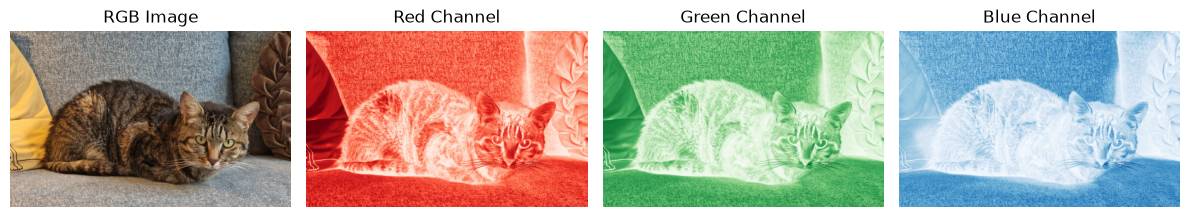

In [ ]:
# Create an RGB image with random colors
img_array = np.array(img)
# Extract channels
red_channel = img_array[:, :, 0]
green_channel = img_array[:, :, 1]
blue_channel = img_array[:, :, 2]

# Create figure layout
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

# Original RGB image
axes[0].imshow(img_array)
axes[0].set_title("RGB Image")
axes[0].axis('off')

# Red channel
axes[1].imshow(red_channel, cmap='Reds')
axes[1].set_title("Red Channel")
axes[1].axis('off')

# Green channel
axes[2].imshow(green_channel, cmap='Greens')
axes[2].set_title("Green Channel")
axes[2].axis('off')

# Blue channel
axes[3].imshow(blue_channel, cmap='Blues')
axes[3].set_title("Blue Channel")
axes[3].axis('off')

plt.tight_layout()
plt.show()

#### A note on numbers in NumPy
| Property | Python `int` | NumPy `int64` | Python `float` | NumPy `float64` |
|:-|:-|:-|:-|:-|
| Number Type | Integer | Integer | Real / Decimal | Real / Decimal |
| Memory Size | Dynamic (≥28 bytes) | Fixed (8 bytes) | Fixed (≈24 bytes object) | Fixed (8 bytes raw) 
| Value Limits | Infinite (RAM bound)| $−2^{63}$ to $2^{63}−1$ | $≈±1.79×10^{308}$ | $≈±1.79×10^{308}$ |
| Overflow Behavior | Never overflows | Wraps around / Errors | Results in Inf | Results in inf |
| Primary Purpose | Everyday Python scripts | Vectorized math & array speed | Everyday decimal math | High-performance linear algebra |

There are also other formats: `bool`, `int8`, `uint8`, `int16`, `uint16`, `int32`, `uint32`, `float8`, `float16`, `float32`, +++

## Creating arrays

### Numbers with fixed spacing: `linspace(a, b)`
* Creates array with 50 numbers from a to b
* Both a and b er included
* Fixed interval between numbers: $(b−a)/49$
* You get an array with 100 numbers using `linspace(a, b, num=100)`

In [34]:
np.linspace(1, 50)

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13.,
       14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25., 26.,
       27., 28., 29., 30., 31., 32., 33., 34., 35., 36., 37., 38., 39.,
       40., 41., 42., 43., 44., 45., 46., 47., 48., 49., 50.])

In [35]:
np.linspace(0, 1, num=11)

array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ])

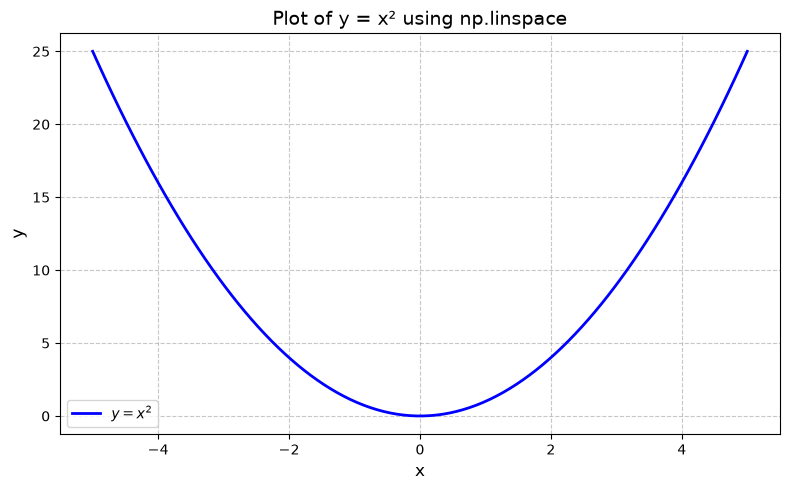

In [134]:
# Generate 100 evenly spaced points between -5 and 5
x = np.linspace(-5, 5, 100)

# Define the function y = x^2
y = x ** 2

# Plot the function
plt.figure(figsize=(8, 5))
plt.plot(x, y, label=r'$y = x^2$', color='blue', linewidth=2)

# Add labels, title, and grid
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title('Plot of y = x² using np.linspace', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()

# Show the plot
plt.show()


### Numbers with logarithmic spacing: `logspace(a, b)`
* Creates array with 50 numbers from $10^a$ to $10^b$
* Both $10^a$ and $10^b$ are included
* Logarithmic distance between numbers (fixed factor)

In [36]:
np.logspace(-1, 1, num=10)

array([ 0.1       ,  0.16681005,  0.27825594,  0.46415888,  0.77426368,
        1.29154967,  2.15443469,  3.59381366,  5.9948425 , 10.        ])

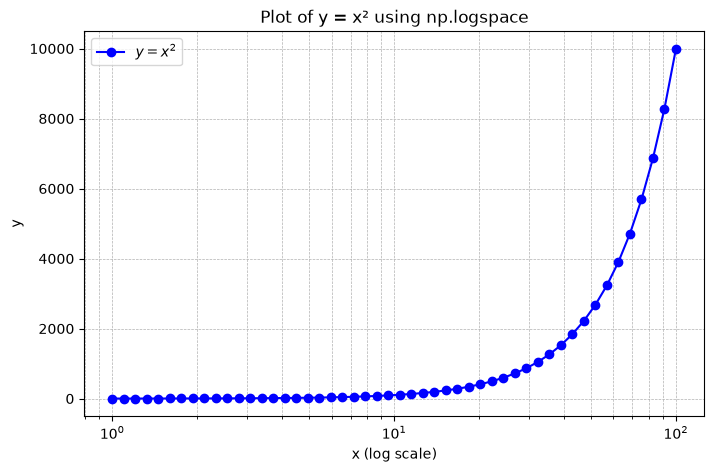

In [135]:
# Generate values spaced evenly on a log scale
# Start exponent = 0 (10^0 = 1), stop exponent = 2 (10^2 = 100)
# 50 points between 1 and 100
x = np.logspace(0, 2, num=50, base=10.0)

# Simple function: y = x^2
y = x ** 2

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x, y, marker='o', linestyle='-', color='blue', label=r'$y = x^2$')

# Set log scale for x-axis to match spacing
plt.xscale('log')

# Labels and title
plt.xlabel('x (log scale)')
plt.ylabel('y')
plt.title('Plot of y = x² using np.logspace')
plt.grid(True, which="both", ls="--", linewidth=0.5)
plt.legend()

# Show plot
plt.show()

### Random numbers
* Use random number generator to fill the array
* Generates an array filled with random floating-point values sampled from a uniform distribution over the interval $[0.0, 1.0)$.

In [42]:
np.random.rand(2, 2)

array([[0.97473495, 0.77356517],
       [0.66134227, 0.5754287 ]])

### Some other functions generating arrays
* These functions take shape as first argument, data type is optional (default is `float64`)
* `zeros()`: array of zeros of given size
* `ones()`: array of ones of given size
* `empty()`: array with uninitialized data
* `arange()`: similar to range, really useful only for arrays of integers
* *_like(): create array with same shape as argument
    * `zeros_like(a)`: creates an array of zeros with the same shape as a

In [37]:
np.ones([2, 3])  # 2x3 matrix of 1.0

array([[1., 1., 1.],
       [1., 1., 1.]])

* Note that empty allocates a block of memory for the specified shape and data type, but does not write any values to it.
* The entries you see are whatever random bits happened to exist in that memory block at the moment of allocation.

In [43]:
np.empty(3)  # 3x1 vector filled with some numbers

array([3.5e-323, 4.0e-323, 4.4e-323])

### Working with data in multiple dimensions
* We will stick to one and two dimensions here
* Key concepts:
    * Operations are applied element-wise if both operands have same size
    * Otherwise, NumPy attempts to <i>broadcast</i>
        * The smaller operand is replicated as many times as necessary to create an array that matches the larger operand
        * The operation is then applied element-wise
        * This allows NumPy to perform operations between arrays of different shapes without taking up unnecessary memory

### Example: array and array of same size

In [147]:
a = np.array([[1, 2], [3, 4], [5, 6]])
b = np.array([[10, 20], [30, 40], [50, 60]])
print(a)
print("Shape of a: ", a.shape)
print(b)
print("Shape of b: ", b.shape)

[[1 2]
 [3 4]
 [5 6]]
Shape of a:  (3, 2)
[[10 20]
 [30 40]
 [50 60]]
Shape of b:  (3, 2)


In [49]:
a + b

array([[11, 22],
       [33, 44],
       [55, 66]])

In [ ]:
# A reminder about how addition of Python lists work
list_1 = [1, 1, 1, 1]
list_2 = [1, 2, 3, 4]
list_1 + list_2

[1, 1, 1, 1, 1, 2, 3, 4]

In [55]:
# Addition of NumPy arrays is element-wise
array_1 = np.array([1, 1, 1, 1])
array_2 = np.array([1, 2, 3, 4])
array_1 + array_2

array([2, 3, 4, 5])

In [50]:
a * b

array([[ 10,  40],
       [ 90, 160],
       [250, 360]])

* Note: This is element-wise multiplication, not matrix multiplication in mathematical sense!

### Mathematical matrix-matrix/matrix-vector multiplication
* First factor must have as many columns as the second has rows
* a and b are both 3x2, so we get an error if we try matrix multiplication here

In [ ]:
a @ b  # mathematical matrix multiplication

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 2)

* If we transpose b (flip about diagonal) to make it 2x3, the dimensions are compatible

In [ ]:
b.T  # b transposed

array([[10, 30, 50],
       [20, 40, 60]])

In [57]:
a @ b.T

array([[ 50, 110, 170],
       [110, 250, 390],
       [170, 390, 610]])

### Example: array and scalar

In [146]:
a

array([10,  2,  3,  4,  5])

In [120]:
a + 100

array([[101, 102],
       [103, 104],
       [105, 106]])

In [121]:
a * 2

array([[ 2,  4],
       [ 6,  8],
       [10, 12]])

In [122]:
a ** 2

array([[ 1,  4],
       [ 9, 16],
       [25, 36]])

## Example: 2D- and 1D arrays (matrix and vector)

In [63]:
c = np.array([100, 200])  # 1D array (vector)
c

array([100, 200])

In [66]:
a + c

array([[101, 202],
       [103, 204],
       [105, 206]])

* c has been added to each row of a: broadcasting
* What happens for 3-element array?

In [67]:
d = np.array([10, 20, 30])
d

array([10, 20, 30])

In [68]:
a + d

ValueError: operands could not be broadcast together with shapes (3,2) (3,) 

* NumPy sees d as 1x3 vector, so shape does not fit
* Need to transpose first!
* But because d has only one dimension, transposing it has no effect

In [69]:
d.T

array([10, 20, 30])

* We need to define a two-dimensional array that has one row and three columns (note the extra brackets!) that can be transposed

In [70]:
dd = np.array([[10, 20, 30]])
dd

array([[10, 20, 30]])

In [71]:
dd.T

array([[10],
       [20],
       [30]])

In [72]:
a + dd.T

array([[11, 12],
       [23, 24],
       [35, 36]])

## Arrays vs Lists
* NumPy arrays differ in several ways from Python lists, especially
    * arrays have fixed size
    * all entries in an array have the same data type (exceptions apply)
* This makes arrays much more efficient in time and space than lists
* How would you double all elements in a Python list? And how would you do this for a 1D NumPy array?

In [ ]:
# Python approach:
py_list = [1, 2, 3, 4]
py_doubled = #
print(py_doubled)

# NumPy approach (vectorized):
np_array = np.array([1, 2, 3, 4])
np_doubled = #
print(np_doubled)

[11 22 33]
[100 400 900]


### Performance comparison
* List and array with 1.000.000 entries
* Compute sine of all elements

In [80]:
lx = list(range(0, 1000000))
ax = np.array(lx)

In [81]:
# Calculate the sine of every element in the list lx
import math  # to use the math.sin() function
%timeit sinlx = [math.sin(x) for x in lx]

66.8 ms ± 542 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [82]:
# Calculate the sine of every element in the array nx
%timeit sinax = np.sin(ax)

5.26 ms ± 71.5 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


* We use `%timeit` to compare computation times here (benchmarking)
    * This is an example of Jupyter/IPython [magic](https://ipython.readthedocs.io/en/stable/interactive/magics.html)
    * It runs everything that follows on the line, taking time with a stopwatch
    * repeats the timing several times to get statistics on fluctuations
    * to ensure reasonably accurate timing, it executes (loops) the command many times until runtime is at least 0.2s

In [ ]:
%timeit?

In [84]:
sinlx = [math.sin(x) for x in lx]
sinax = np.sin(ax)
all(sinlx == sinax)

True

* NumPy is significantly faster than list comprehension
* This applies mainly when we apply NumPy functions to large arrays
* For scalars, `math` functions are usually faster than `numpy` functions

## Arrays slices are view: An important difference from lists
* Array slices are so-called views:
    * If a is a Numpy array, and `b = a[m:n:s]`, then b is a <i>view</i> of array a
    * a and b are distinct objects (i.e., `id(a) != id(b)`)
    * a and b are both of type `numpy.ndarray`
    * a and b share the same underlying data: b just restricts what we see of the data in a
    * Therefore, any change to data in b also affects data in a

In [138]:
# Lists
ls1 = [1, 2, 3, 4, 5]
ls2 = ls1[:3]
ls2[0] = 10
print("lists:")
print(ls1)
print(ls2)

a = np.array([1, 2, 3, 4, 5])
b = a[:3]
print(id(a))
print(id(b))
b[0] = 10
print("arrays:")
print(a)
print(b)

lists:
[1, 2, 3, 4, 5]
[10, 2, 3]
2386688636368
2386576300848
arrays:
[10  2  3  4  5]
[10  2  3]


* For a normal Python list `l`, `l[:]` is a copy  of the elements in `l`, <br>i.e., a new list object, that can be manipulated without affecting `l`. 
* For an array `a`, `a[:]` is a view of a with the same underlying data as `a`<br> and changing data through this view will change the data in `a`.
* The issues with copying that we discussed earlier for lists are also precent for arrays

In [149]:
b = a.copy()  # Creates a copy rather than a view
b[0][0] = 10
print(a)
print(b)

[[1 2]
 [3 4]
 [5 6]]
[[10  2]
 [ 3  4]
 [ 5  6]]


## Pandas series and dataframes

### Pandas
* Powerful and widely popular package for data processing
* Originally geared towards applications in finance
* Focus on managing data
* Can be considered Python's answer to spreadsheets
* Similar to R's data frames
* Some support for data analysis and visualization

### Key concepts
* Series, roughly comparable to single columns in a spreadsheet
* DataFrame, roughly comparable to an entire table or spreadsheet
* Builds on NumPy, but adds names to dataprovides powerful high-level tools to work with tables